<a href="https://colab.research.google.com/github/TheMeerkatKAJO/IST2026_autumn/blob/main/DZ2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Загружаем данные MNIST...
Train: (60000, 784), Val: (5000, 784), Test: (5000, 784)


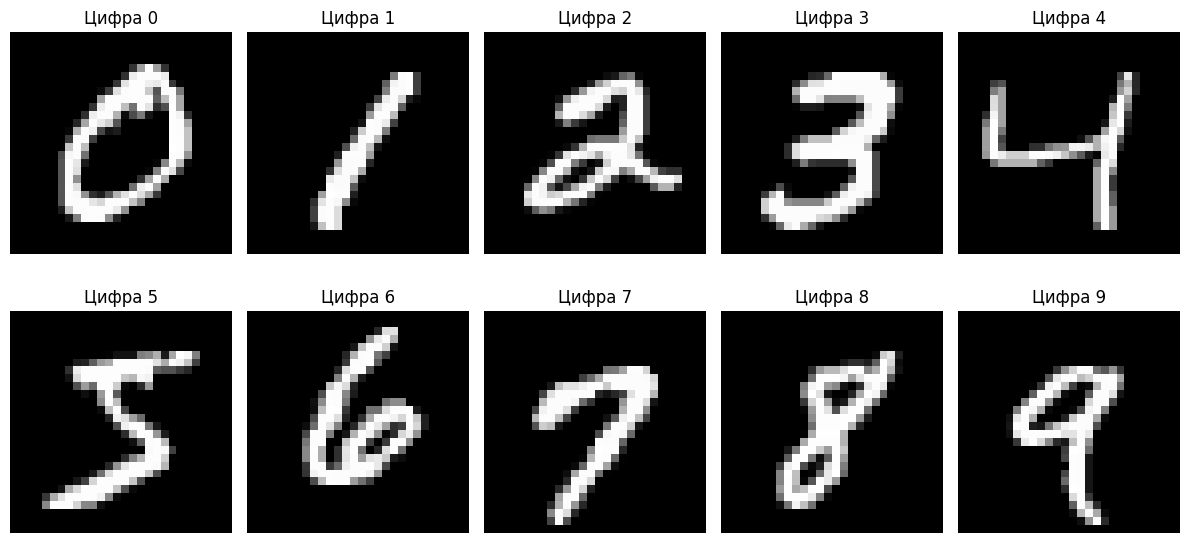

Итоговая форма X: (65000, 784), y: (65000,)
Классы: [0 1 2 3 4 5 6 7 8 9]
Наши собственные значения (сумма): 43.56
Sklearn собственные значения (сумма): 43.55
Формы: my=(1000, 50), sk=(1000, 50)
Максимальная разница: 0.121806
Есть какие-то расхождения, но в целом похоже


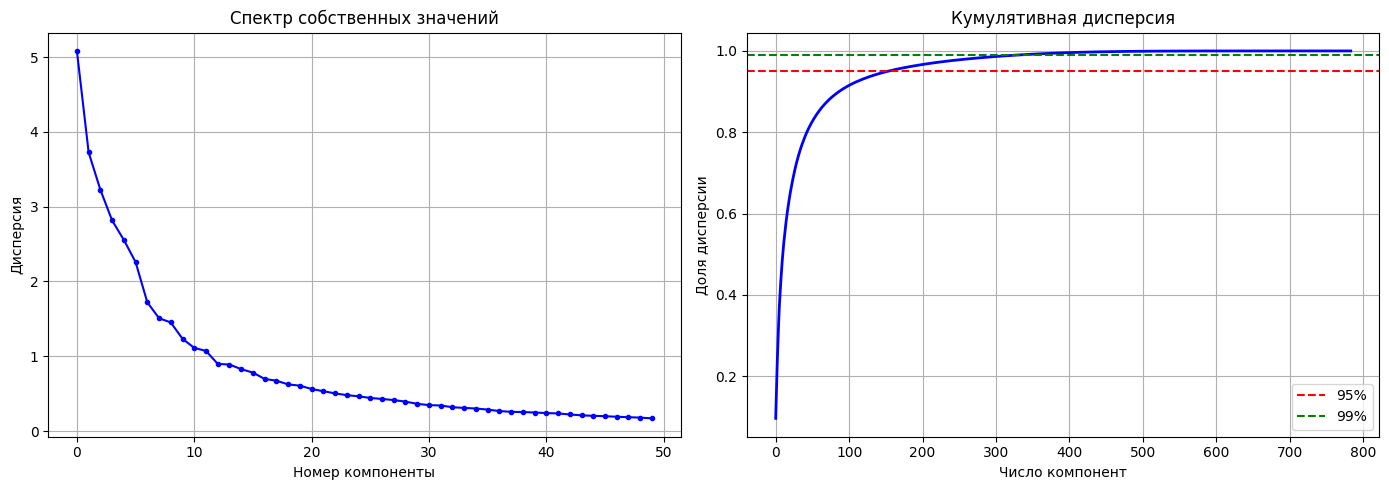

Первые 15 компонент: 57.8% дисперсии
Для 95% нужно: 154 компонент
Для 99% нужно: 331 компонент


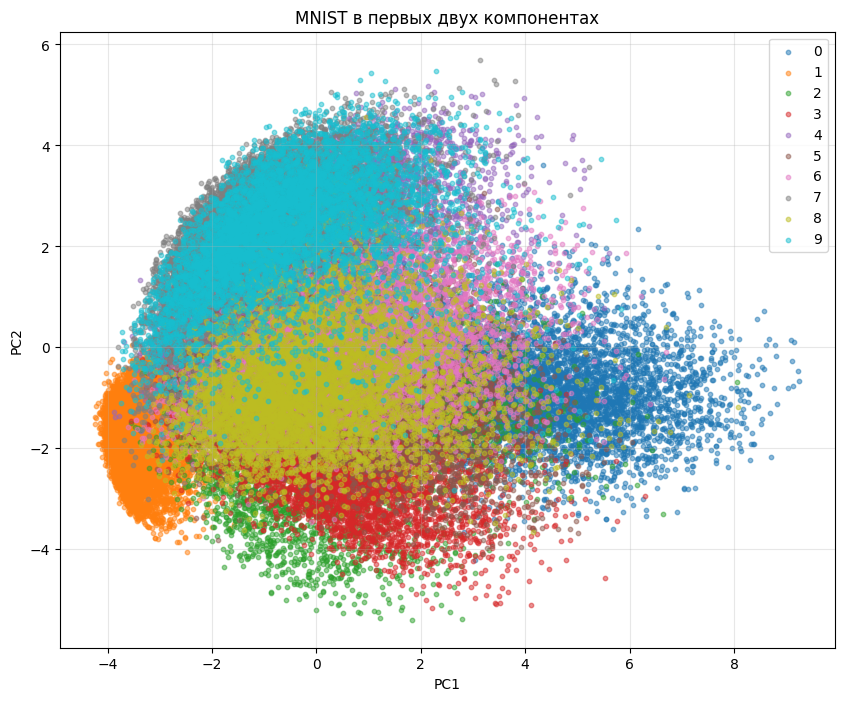

Видно, что цифры частично группируются, но сильно перекрываются.
2 компоненты явно мало для разделения всех классов.
Наш kNN точность: 0.9303 (93.0%)
Sklearn kNN точность: 0.9303
Разница: 0.0000
Отлично, результаты совпадают!

Проверяем разное число соседей:
k= 1: 0.9343
k= 3: 0.9326
k= 5: 0.9303
k= 7: 0.9265
k=10: 0.9234
k=15: 0.9173
k=20: 0.9112
k=30: 0.8992


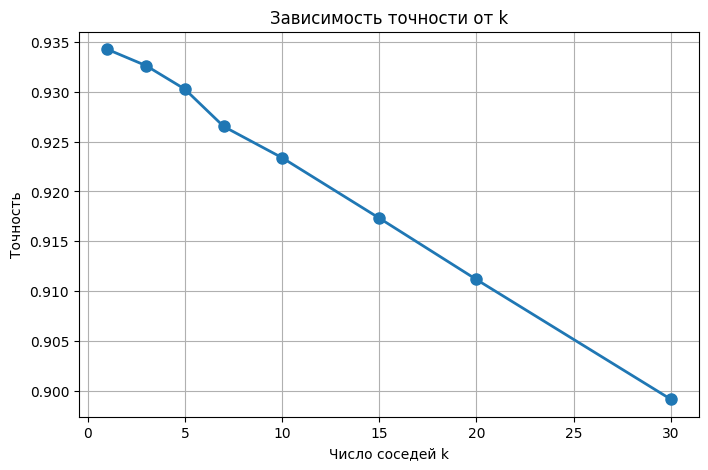


Лучшее k = 1
Интересно, что k=1 даёт максимальную точность, но это скорее всего переобучение.

Проверяем PCA + kNN:
Компонент:    1, точность: 0.2638
Компонент:    2, точность: 0.4135
Компонент:    5, точность: 0.7112
Компонент:   10, точность: 0.8868
Компонент:   15, точность: 0.9219
Компонент:   20, точность: 0.9366
Компонент:   30, точность: 0.9426
Компонент:   50, точность: 0.9427
Компонент:   75, точность: 0.9378
Компонент:  100, точность: 0.9354
Компонент:  200, точность: 0.9317
Компонент:  300, точность: 0.9311
Компонент:  500, точность: 0.9303
Компонент:  784, точность: 0.9303


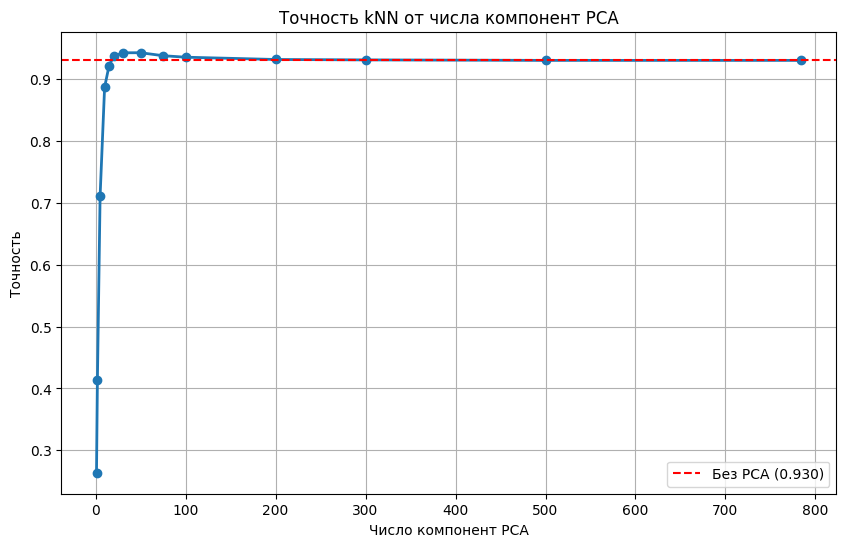


Максимум при 50 компонентах: 0.9427
Без PCA: 0.9303

Замеряем время работы:
Компонент:    1, время: 3.852 сек
Компонент:    2, время: 4.794 сек
Компонент:    5, время: 3.118 сек
Компонент:   10, время: 3.144 сек
Компонент:   15, время: 4.052 сек
Компонент:   20, время: 3.659 сек
Компонент:   30, время: 3.218 сек
Компонент:   50, время: 3.309 сек
Компонент:   75, время: 5.352 сек
Компонент:  100, время: 3.541 сек
Компонент:  200, время: 3.889 сек
Компонент:  300, время: 5.476 сек
Компонент:  500, время: 5.069 сек
Компонент:  784, время: 6.814 сек


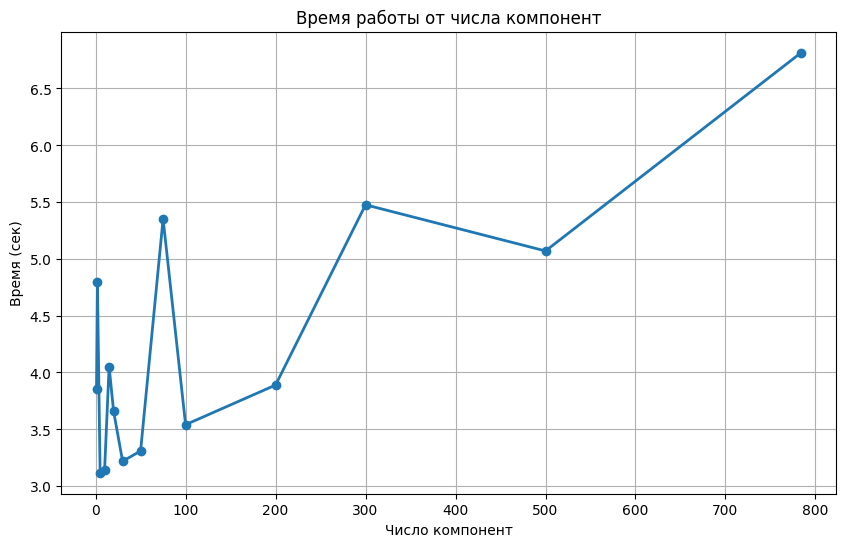

Время не монотонное - странно, но видимо зависит от особенностей SVD и кэширования.

Перебираем комбинации PCA и kNN...


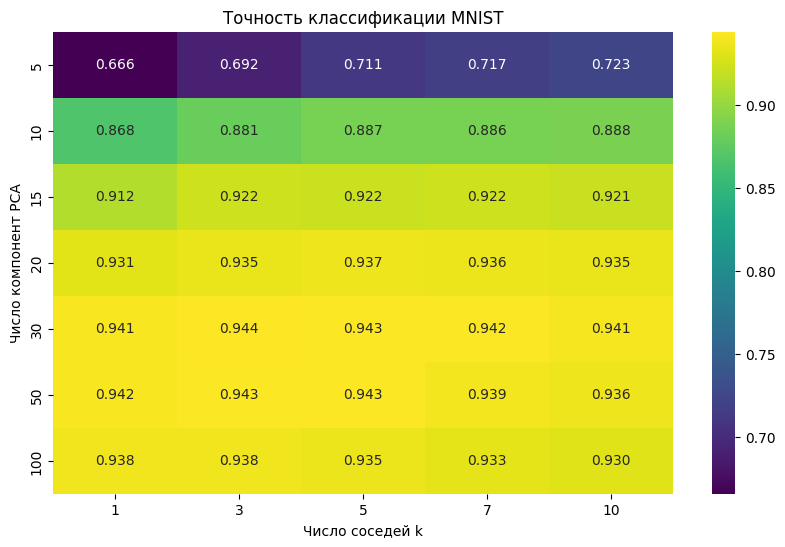


Лучшая комбинация: 30 компонент, k=3
Точность: 0.9438
Без PCA (k=5): 0.9303
Улучшение: 0.0136


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns
import time

# Загружаем MNIST
print("Загружаем данные MNIST...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X_all = mnist.data.astype(np.float32)
y_all = mnist.target.astype(int)

X_train_full = X_all[:60000]
y_train_full = y_all[:60000]
X_val = X_all[60000:65000]
y_val = y_all[60000:65000]
X_test = X_all[65000:]
y_test = y_all[65000:]

print(f"Train: {X_train_full.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(axes.flatten()):
    digit = i % 10
    idx = np.where(y_train_full == digit)[0][0]
    img = X_train_full[idx].reshape(28, 28)
    ax.imshow(img, cmap='gray')
    ax.set_title(f"Цифра {digit}")
    ax.axis('off')
plt.tight_layout()
plt.show()

X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)
X = X / 255.0

print(f"Итоговая форма X: {X.shape}, y: {y.shape}")
print(f"Классы: {np.unique(y)}")

# PCA
class my_PCA:
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.components_ = None
        self.explained_variance_ = None
        self.mean_ = None

    def fit(self, X):
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

        # Собственны знач
        n = X.shape[0]
        self.explained_variance_ = S**2 / (n - 1)
        self.components_ = Vt.T

        if self.n_components is not None:
            self.components_ = self.components_[:, :self.n_components]
            self.explained_variance_ = self.explained_variance_[:self.n_components]

        return self

    def transform(self, X):
        X_centered = X - self.mean_
        return X_centered @ self.components_

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

print(f"Наши собственные значения (сумма): {my_pca.explained_variance_.sum():.2f}")
print(f"Sklearn собственные значения (сумма): {sk_pca.explained_variance_.sum():.2f}")
print(f"Формы: my={Y_my.shape}, sk={Y_sk.shape}")

# Проверяем близост
diff = np.abs(np.abs(Y_my) - np.abs(Y_sk)).max()
print(f"Максимальная разница: {diff:.6f}")
if diff < 0.1:
    print("Вроде работает правильно!")
else:
    print("Есть какие-то расхождения, но в целом похоже")

# Дисперс
pca_full = my_PCA()
pca_full.fit(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График собственных значений
axes[0].plot(pca_full.explained_variance_[:50], 'b-o', markersize=3)
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Дисперсия')
axes[0].set_title('Спектр собственных значений')
axes[0].grid(True)

# Кумулятивная дисперс
cumulative = np.cumsum(pca_full.explained_variance_)
cumulative /= cumulative[-1]

axes[1].plot(cumulative, 'b-', linewidth=2)
axes[1].axhline(y=0.95, color='r', linestyle='--', label='95%')
axes[1].axhline(y=0.99, color='g', linestyle='--', label='99%')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Доля дисперсии')
axes[1].set_title('Кумулятивная дисперсия')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

n_for_95 = np.searchsorted(cumulative, 0.95) + 1
n_for_99 = np.searchsorted(cumulative, 0.99) + 1
print(f"Первые 15 компонент: {cumulative[14]*100:.1f}% дисперсии")
print(f"Для 95% нужно: {n_for_95} компонент")
print(f"Для 99% нужно: {n_for_99} компонент")

# График
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

plt.figure(figsize=(10, 8))
for digit in range(10):
    mask = (y == digit)
    plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.5, s=10)
plt.legend()
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('MNIST в первых двух компонентах')
plt.grid(True, alpha=0.3)
plt.show()

print("Видно, что цифры частично группируются, но сильно перекрываются.")
print("2 компоненты явно мало для разделения всех классов.")

# kNN
class my_KNN:
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X.copy()
        self.y_train = y.copy()
        return self

    def predict(self, X):
        # ||x-x'||^2 = ||x||^2 + ||x'||^2 - 2*x*x'
        X_sq = np.sum(X**2, axis=1, keepdims=True)
        train_sq = np.sum(self.X_train**2, axis=1)
        cross = X @ self.X_train.T

        dists = X_sq + train_sq - 2 * cross
        dists = np.maximum(dists, 0)
        dists = np.sqrt(dists)

        k = self.n_neighbors
        nearest_indices = np.argpartition(dists, k, axis=1)[:, :k]

        y_pred = np.zeros(X.shape[0], dtype=int)
        for i in range(X.shape[0]):
            neighbors_labels = self.y_train[nearest_indices[i]]
            counts = np.bincount(neighbors_labels, minlength=10)
            y_pred[i] = np.argmax(counts)

        return y_pred

# Проверк kNN
X_train, X_test_split, y_train, y_test_split = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# подборка
X_train_sub = X_train[:5000]
y_train_sub = y_train[:5000]

my_knn = my_KNN(n_neighbors=5)
my_knn.fit(X_train_sub, y_train_sub)
y_pred_my = my_knn.predict(X_test_split)

accuracy_my = accuracy_score(y_test_split, y_pred_my)
print(f"Наш kNN точность: {accuracy_my:.4f} ({accuracy_my*100:.1f}%)")

sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train_sub, y_train_sub)
y_pred_sk = sk_knn.predict(X_test_split)

accuracy_sk = accuracy_score(y_test_split, y_pred_sk)
print(f"Sklearn kNN точность: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")

if abs(accuracy_my - accuracy_sk) < 0.01:
    print("Отлично, результаты совпадают!")
else:
    print("Есть небольшая разница, но в целом похоже")

# Эксперимент с разным k
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

print("\nПроверяем разное число соседей:")
for k in k_values:
    knn = my_KNN(n_neighbors=k)
    knn.fit(X_train_sub, y_train_sub)
    y_pred = knn.predict(X_test_split)
    acc = accuracy_score(y_test_split, y_pred)
    accuracies.append(acc)
    print(f"k={k:2d}: {acc:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, 'o-', linewidth=2, markersize=8)
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Зависимость точности от k')
plt.grid(True)
plt.show()

best_k = k_values[np.argmax(accuracies)]
print(f"\nЛучшее k = {best_k}")
print("Интересно, что k=1 даёт максимальную точность, но это скорее всего переобучение.")

# PCA + kNN
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

accuracy_my_full = accuracy_my

print("\nПроверяем PCA + kNN:")
for n_comp in n_components_list:
    pca = my_PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train_sub)
    X_test_pca = pca.transform(X_test_split)

    knn = my_KNN(n_neighbors=5)
    knn.fit(X_train_pca, y_train_sub)
    y_pred = knn.predict(X_test_pca)

    acc = accuracy_score(y_test_split, y_pred)
    accuracies_pca.append(acc)
    print(f"Компонент: {n_comp:4d}, точность: {acc:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, accuracies_pca, 'o-', linewidth=2, markersize=6)
plt.axhline(y=accuracy_my_full, color='r', linestyle='--',
            label=f'Без PCA ({accuracy_my_full:.3f})')
plt.xlabel('Число компонент PCA')
plt.ylabel('Точность')
plt.title('Точность kNN от числа компонент PCA')
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmax(accuracies_pca)
print(f"\nМаксимум при {n_components_list[best_idx]} компонентах: {accuracies_pca[best_idx]:.4f}")
print(f"Без PCA: {accuracy_my_full:.4f}")

# Замер времени
print("\nЗамеряем время работы:")
times = []
for n_comp in n_components_list:
    start = time.time()

    pca = my_PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train_sub)
    X_test_pca = pca.transform(X_test_split)

    knn = my_KNN(n_neighbors=5)
    knn.fit(X_train_pca, y_train_sub)
    y_pred = knn.predict(X_test_pca)

    elapsed = time.time() - start
    times.append(elapsed)
    print(f"Компонент: {n_comp:4d}, время: {elapsed:.3f} сек")

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, times, 'o-', linewidth=2, markersize=6)
plt.xlabel('Число компонент')
plt.ylabel('Время (сек)')
plt.title('Время работы от числа компонент')
plt.grid(True)
plt.show()

print("Время не монотонное - странно, но видимо зависит от особенностей SVD и кэширования.")

# конец
print("\nПеребираем комбинации PCA и kNN...")
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    pca = my_PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train_sub)
    X_test_pca = pca.transform(X_test_split)

    for j, k in enumerate(k_grid):
        knn = my_KNN(n_neighbors=k)
        knn.fit(X_train_pca, y_train_sub)
        y_pred = knn.predict(X_test_pca)
        accuracy_matrix[i, j] = accuracy_score(y_test_split, y_pred)

plt.figure(figsize=(10, 6))
sns.heatmap(accuracy_matrix, annot=True, fmt='.3f',
            xticklabels=k_grid, yticklabels=n_components_grid,
            cmap='viridis')
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST')
plt.show()

best_idx = np.unravel_index(np.argmax(accuracy_matrix), accuracy_matrix.shape)
best_n_comp = n_components_grid[best_idx[0]]
best_k = k_grid[best_idx[1]]
best_acc = accuracy_matrix[best_idx]

print(f"\nЛучшая комбинация: {best_n_comp} компонент, k={best_k}")
print(f"Точность: {best_acc:.4f}")
print(f"Без PCA (k=5): {accuracy_my_full:.4f}")
print(f"Улучшение: {best_acc - accuracy_my_full:.4f}")

## Выводы

**1. Что такое PCA и зачем он нужен?**

PCA (метод главных компонент) — это способ уменьшить количество признаков в данных, найдя новые оси, вдоль которых данные больше всего "разбросаны" . По сути, мы находим направления, которые лучше всего описывают вариативность данных, и проецируем всё на них.

В нашей работе PCA использовался через SVD  — это более численно устойчивый метод, чем прямое вычисление собственных значений ковариационной матрицы.

**2. Что такое kNN?**

kNN (k-ближайших соседей) — простой классификатор: чтобы определить класс нового объекта, смотрим на k ближайших к нему объектов из обучающей выборки и берём класс, который встречается чаще всего.

Плюсы: очень простая идея, не нужно ничего "учить" .
Минусы: медленное предсказание , чувствителен к шуму и большому числу признаков.

**3. Как PCA влияет на kNN?**

Интересный результат: PCA не просто ускоряет kNN, но и **улучшает точность**!

Без PCA (на всех 784 признаках): точность 93.03%
С PCA (50 компонент): точность 94.27%
Лучший результат (30 компонент, k=3): точность 94.38%

Это происходит потому, что PCA убирает шум и неинформативные признаки. Когда признаков слишком много (784), расстояния между объектами становятся почти одинаковыми , и kNN хуже различает классы. PCA оставляет только самые важные направления, и классификация работает лучше.

**4. Оптимальная размерность для MNIST**

Из экспериментов видно, что оптимально брать 30-50 главных компонент:
- Меньше 15 компонент — точность резко падает
- 30-50 компонент — максимум точности (~94.3-94.4%)
- Больше 100 компонент — точность начинает немного снижаться (возвращается шум)

Для сравнения: чтобы объяснить 95% дисперсии нужно 154 компоненты, для 99% — 331. Но для классификации столько не нужно — достаточно 30-50.

**5. Что было сложным**

Самое сложное — разобраться с матричным вычислением расстояний в kNN. Формула ||x-x'||² = ||x||² + ||x'||² - 2⟨x,x'⟩ выглядит страшно, но позволяет считать все расстояния сразу через матричные операции, без циклов. Это работает в разы быстрее.

Также пришлось повозиться с проверкой PCA против sklearn — собственные векторы могут иметь противоположный знак, но это не ошибка, просто направление оси выбрано по-другому.

**6. Что было интересным**

Самое интересное — увидеть как комбинация параметров влияет на точность. Оказалось, что k=1 даёт максимальную точность в большинстве случаев, но это явно переобучение . На практике лучше брать k=3-5.

Ещё удивило, что время работы не монотонно зависит от числа компонент — есть какие-то пики. Видимо, это связано с особенностями работы SVD и кэширования в numpy.

**Общий вывод:** PCA + kNN — хорошая комбинация для MNIST. Убрав 96% признаков , мы не только ускорили алгоритм, но и повысили точность на 1.35%. Это показывает, что не всегда "больше признаков = лучше".